# 06 · Publication maturity, forecast intervals and later outcomes

**Objective:** extend the forecasting experiment with publisher timing evidence, separately calibrated
uncertainty, later-acquired outcomes and an immutable future-forecast registration.

The [publisher overview](https://data.ny.gov/api/views/gxb3-akrn/files/59feac4c-ab4f-44e1-b4bd-188b5edfcc20?filename=MTA_BusHourlyRidership_Overview.pdf)
(page 4) warns that counts within two weeks of posting undercount ridership and historical counts
can be revised. It describes daily releases; portal metadata lists weekly posting. Cadence therefore
does not establish an exact first-publication delay. This experiment uses **14 complete excluded dates**
as a maturity policy, not a guarantee that counts are final. The original seven-day study is preserved.

Historical input vintages remain unavailable. Calibration and evaluation are retrospective and the
earlier EDA examined these dates. Empirical interval coverage is measured; distribution-free or
future coverage guarantees are not claimed. A new snapshot is kept outside the frozen original collection.

In [1]:
from pathlib import Path
import sys,json,pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'scripts/forecast_intervals.py').exists())
sys.path.insert(0,str(ROOT/'scripts'))
from forecasting import (load_inputs,make_examples,issue_cutoff,backtest,metrics,training_rows,
                         fit_model,predict,sha256,BASELINES,CONFIGS,FEATURES)
from forecast_intervals import (load_snapshot,monitoring_view,calibrate,apply_intervals,
                               interval_metrics,register_forecast,evaluate_registration)
SNAPSHOT='data/raw/new_york_monitoring/20261105T134740Z'
OUT=ROOT/'data/processed/new_york/forecasting_followup'
REPORT=ROOT/'reports/forecasting_intervals'
OUT.mkdir(parents=True,exist_ok=True)
(REPORT/'figures').mkdir(parents=True,exist_ok=True)
MATURITY=14
original,routes=load_inputs(ROOT)
latest,poll=load_snapshot(ROOT,SNAPSHOT)
ASOF=pd.Timestamp(poll['observed_utc']).tz_convert('America/New_York').tz_localize(None).normalize()
available_cutoff=ASOF-pd.Timedelta(days=MATURITY+1)
combined,network=monitoring_view(original,latest,routes)
display(pd.DataFrame([{'snapshot_date':ASOF.date(),'latest_source_date':latest.payment_date.max().date(),
    'mature_target_cutoff':available_cutoff.date(),'new_route_dates':poll['later_route_dates'],
    'overlap_route_dates':poll['overlap_rows'],'changed_overlap_rows':poll['changed_overlap_rows'],
    'portal_posting_frequency':poll['posting_frequency']}]))
print('Denominator checks passed:',poll['denominator_checks_passed'])

,snapshot_date,latest_source_date,mature_target_cutoff,new_route_dates,overlap_route_dates,changed_overlap_rows,portal_posting_frequency
0,2026-11-05,2026-10-27,2026-10-21,1107,1230,0,Weekly


Denominator checks passed: True


## 1. Preserve source versions and expose maturity

The 5 November snapshot contains route/date aggregates from 1 September through 27 October.
Compare overlapping September values with the frozen collection before using any later rows.
First-seen timestamps describe this collection, not actual first-publication timestamps. Missing
hours, incomplete cohort dates and unusually low network totals trigger review without zero filling.
Older quality exclusions remain in force. Only outcomes through 21 October are mature under this policy.

A public revision-API read returned 404. This does not establish that publisher archives do not exist.
Snapshot collection now supplies dated versions for future comparisons; it cannot reconstruct old vintages.

In [2]:
display(pd.DataFrame([{'start':latest.payment_date.min(),'end':latest.payment_date.max(),
    'route_dates':len(latest),'mature_new_route_dates':int((latest.payment_date.gt(original.payment_date.max()) & latest.payment_date.le(available_cutoff)).sum()),
    'new_masked_rows':int(combined.loc[combined.payment_date.gt(original.payment_date.max()),'analysis_boardings'].isna().sum())}]))
display(network.tail(10))
display(pd.DataFrame(poll.get('errors',[])))

,start,end,route_dates,mature_new_route_dates,new_masked_rows
0,2026-09-01,2026-10-27,2337,861,82


,payment_date,total,routes,review
655,2026-10-18,163787,41,False
656,2026-10-19,275277,41,False
657,2026-10-20,289987,41,False
658,2026-10-21,290638,41,False
659,2026-10-22,292041,41,False
660,2026-10-23,275803,41,False
661,2026-10-24,205881,41,False
662,2026-10-25,170551,41,False
663,2026-10-26,0,41,True
664,2026-10-27,0,41,True


,url,file,error
0,https://data.ny.gov/api/views/gxb3-akrn/revisi...,public_revisions.json,HTTP Error 404: Not Found


## 2. Define a maturity-aware calibration experiment

Repeat the same fixed candidate family under the 14-complete-day policy. Select by MAE on six
validation origins, 1 June-6 July (targets through 12 July). All selection outcomes are available by
the first calibration origin, 27 July, under the same maturity policy.

Calibration uses four origins, 27 July-17 August, with targets through 23 August. Freeze calibration
quantiles before testing on three later origins, 7-21 September (targets through 27 September).
All calibration targets are available by the first evaluation cutoff, 23 August. These explicit gaps
prevent the release-delay rule from being violated at model selection or interval calibration.

Four available same-weekday values supply seasonal predictors. Under a 14-day holdback their dates
are t-21/28/35/42; the inherited lag column names are slots, not literal ages in this follow-up.

In [3]:
origins=pd.date_range('2025-03-03','2026-10-19',freq='W-MON')
examples=make_examples(combined,routes,origins,MATURITY)
validation_origins=pd.date_range('2026-06-01','2026-07-06',freq='W-MON')
calibration_origins=pd.date_range('2026-07-27','2026-08-17',freq='W-MON')
evaluation_origins=pd.date_range('2026-09-07','2026-09-21',freq='W-MON')
assert validation_origins.max()+pd.Timedelta(days=6)<=issue_cutoff(calibration_origins.min(),MATURITY)
assert calibration_origins.max()+pd.Timedelta(days=6)<=issue_cutoff(evaluation_origins.min(),MATURITY)
display(pd.DataFrame([{'stage':name,'first_origin':values.min(),'last_origin':values.max(),
    'last_target':values.max()+pd.Timedelta(days=6),'first_available_cutoff':issue_cutoff(values.min(),MATURITY)}
    for name,values in [('validation',validation_origins),('calibration',calibration_origins),('evaluation',evaluation_origins)]]))

,stage,first_origin,last_origin,last_target,first_available_cutoff
0,validation,2026-06-01,2026-07-06,2026-07-12,2026-05-17
1,calibration,2026-07-27,2026-08-17,2026-08-23,2026-07-12
2,evaluation,2026-09-07,2026-09-21,2026-09-27,2026-08-23


In [4]:
validation,validation_audit=backtest(examples,validation_origins,BASELINES+list(CONFIGS),MATURITY)
validation_scores=metrics(validation).sort_values(['mae','model']).reset_index(drop=True)
selected=validation_scores.iloc[0].model
baseline=validation_scores.loc[validation_scores.model.isin(BASELINES)].iloc[0].model
display(validation_scores.round(3))
print('Selection frozen before calibration/evaluation:',selected)

Origin 2026-06-01: 17,835 training / 287 scored rows


Origin 2026-06-08: 18,122 training / 287 scored rows


Origin 2026-06-15: 18,409 training / 287 scored rows


Origin 2026-06-22: 18,696 training / 287 scored rows


Origin 2026-06-29: 18,983 training / 287 scored rows


Origin 2026-07-06: 19,270 training / 287 scored rows


,model,rows,routes,mae,rmse,wape,bias,actual_total
0,boosted_15,1722,41,474.157,750.681,0.088,128.772,9247206.0
1,boosted_31,1722,41,484.394,746.784,0.090,116.167,9247206.0
2,seasonal_mean4,1722,41,537.463,918.028,0.100,286.309,9247206.0
3,seasonal_latest,1722,41,680.945,1146.210,0.127,235.104,9247206.0


Selection frozen before calibration/evaluation: boosted_15


## 3. Calibrate 80% and 90% empirical intervals

Normalize each absolute calibration error by max(available four-week seasonal mean, 100 boardings).
The fixed 100-boarding floor prevents unstable division near zero. For level p, use sorted residual
rank ceil((n+1)*p), rejecting a rank larger than the calibration sample. Bounds are prediction plus/minus
that residual quantile times the available seasonal scale; the lower bound is clipped to zero.

Scale choices and levels are fixed before interval evaluation. Dependence across routes and dates,
weekly model refitting and distribution shift invalidate a general exchangeability guarantee. These
are empirically calibrated intervals, and achieved coverage may differ substantially from the nominal level.

In [5]:
calibration_predictions,calibration_audit=backtest(examples,calibration_origins,[selected],MATURITY)
calibration=calibrate(calibration_predictions,examples,issue_cutoff(evaluation_origins.min(),MATURITY))
display(pd.DataFrame([{'nominal_level':float(level),'scaled_error_quantile':value,
    'calibration_rows':calibration['rows'],'last_calibration_target':calibration['last_calibration_target']}
    for level,value in calibration['levels'].items()]))

Origin 2026-07-27: 20,131 training / 287 scored rows


Origin 2026-08-03: 20,418 training / 287 scored rows


Origin 2026-08-10: 20,705 training / 246 scored rows


Origin 2026-08-17: 20,992 training / 287 scored rows


,nominal_level,scaled_error_quantile,calibration_rows,last_calibration_target
0,0.8,0.150460,1107,2026-08-23
1,0.9,0.215301,1107,2026-08-23


In [6]:
evaluation,evaluation_audit=backtest(examples,evaluation_origins,list(dict.fromkeys([selected,baseline])),MATURITY)
evaluation_scores=metrics(evaluation)
selected_evaluation=evaluation.loc[evaluation.model.eq(selected)].copy()
intervals=apply_intervals(selected_evaluation,examples,calibration)
coverage=interval_metrics(intervals)
route_coverage=interval_metrics(intervals,('level','bus_route'))
weekly_coverage=interval_metrics(intervals,('level','origin'))
assert intervals.lower.ge(0).all() and intervals.upper.ge(intervals.lower).all()
display(evaluation_scores.round(3))
display(coverage.round(3))
display(weekly_coverage.round(3))
display(route_coverage.loc[route_coverage.level.eq(.9)].sort_values('coverage').head(10).round(3))

Origin 2026-09-07: 21,812 training / 287 scored rows


Origin 2026-09-14: 22,099 training / 287 scored rows


Origin 2026-09-21: 22,386 training / 287 scored rows


,model,rows,routes,mae,rmse,wape,bias,actual_total
0,boosted_15,861,41,903.435,1259.872,0.156,-554.698,4985438.0
1,seasonal_mean4,861,41,1008.428,1425.578,0.174,-572.459,4985438.0


,level,rows,coverage,mean_width,mean_interval_score
0,0.8,861,0.455,1570.356,4527.291
1,0.9,861,0.628,2247.084,5390.384


,level,origin,rows,coverage,mean_width,mean_interval_score
0,0.8,2026-09-07,287,0.585,1586.379,3247.055
1,0.8,2026-09-14,287,0.341,1560.192,5975.776
2,0.8,2026-09-21,287,0.439,1564.498,4359.042
3,0.9,2026-09-07,287,0.770,2270.015,3790.270
4,0.9,2026-09-14,287,0.512,2232.537,7239.840
5,0.9,2026-09-21,287,0.603,2238.699,5141.041


,level,bus_route,rows,coverage,mean_width,mean_interval_score
47,0.9,M106,21,0.190,429.363,2832.501
81,0.9,M98,21,0.238,274.735,2877.352
73,0.9,M66,21,0.286,1704.179,12115.314
42,0.9,M10,21,0.286,1135.639,7555.198
46,0.9,M104,21,0.333,2084.467,14811.433
75,0.9,M72,21,0.381,1167.203,4395.224
65,0.9,M35,21,0.381,101.075,4339.392
59,0.9,M22,21,0.429,455.338,2763.989
49,0.9,M116,21,0.429,1463.784,5556.027
80,0.9,M96,21,0.476,3113.158,13881.483


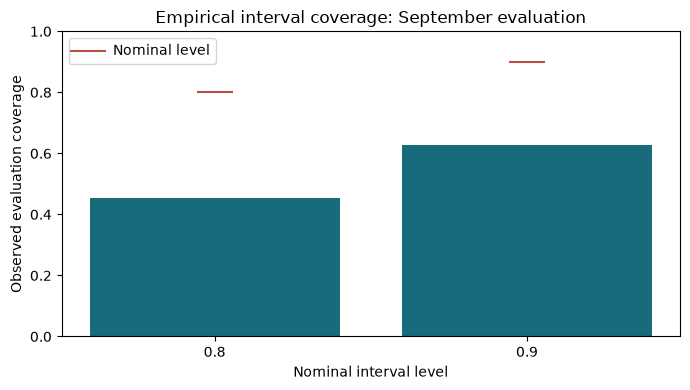

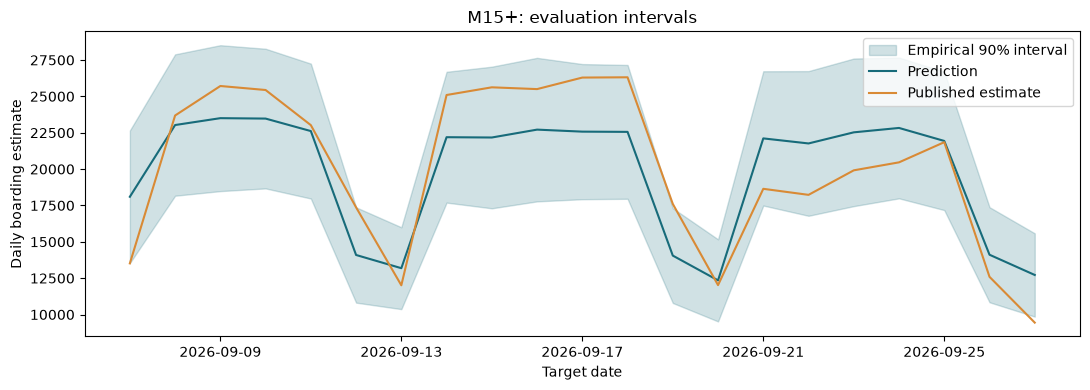

In [7]:
fig,ax=plt.subplots(figsize=(7,4))
ax.bar(coverage.level.astype(str),coverage.coverage,color='#176b7a')
ax.scatter(coverage.level.astype(str),coverage.level,color='#c34b46',marker='_',s=700,label='Nominal level')
ax.set(ylim=(0,1),xlabel='Nominal interval level',ylabel='Observed evaluation coverage',title='Empirical interval coverage: September evaluation')
ax.legend();plt.tight_layout();plt.savefig(REPORT/'figures/interval_coverage.png',dpi=160);plt.show()
sample_route=selected_evaluation.groupby('bus_route').actual.sum().idxmax()
part=intervals.loc[intervals.bus_route.eq(sample_route)&intervals.level.eq(.9)].sort_values('payment_date')
fig,ax=plt.subplots(figsize=(11,4))
ax.fill_between(part.payment_date,part.lower,part.upper,alpha=.2,color='#176b7a',label='Empirical 90% interval')
ax.plot(part.payment_date,part.prediction,label='Prediction',color='#176b7a')
ax.plot(part.payment_date,part.actual,label='Published estimate',color='#d98a35')
ax.set(title=f'{sample_route}: evaluation intervals',xlabel='Target date',ylabel='Daily boarding estimate')
ax.legend();plt.tight_layout();plt.savefig(REPORT/'figures/example_intervals.png',dpi=160);plt.show()

## 4. Score the preserved October forecast using later-acquired outcomes

The original notebook saved forecasts for 5-11 October before this new outcome collection.
Load those predictions unchanged and score them only where later targets pass the maturity and
quality rules. Compare with the original seasonal baseline built from the original frozen inputs.
This is later-acquired outcome evaluation of a retrospective outlook, not a forecast issued in October.
Do not refit or change that original model after seeing these labels.

In [8]:
legacy_folder=ROOT/'data/processed/new_york/forecasting'
legacy_manifest=json.loads((legacy_folder/'forecast_manifest.json').read_text())
assert sha256(legacy_folder/'illustrative_forecast.csv')==legacy_manifest['products']['illustrative_forecast']['sha256']
legacy=pd.read_csv(legacy_folder/'illustrative_forecast.csv',dtype={'bus_route':'string'},parse_dates=['origin','payment_date'])
targets=combined.loc[combined.payment_date.le(available_cutoff),['bus_route','payment_date','analysis_boardings']]
scored=legacy.merge(targets,on=['bus_route','payment_date'],validate='one_to_one').rename(columns={'analysis_boardings':'actual'})
scored=scored.loc[scored.actual.notna()].copy()
legacy_examples=make_examples(original,routes,[legacy.origin.iloc[0]],7)
legacy_baseline=scored.drop(columns='prediction').merge(legacy_examples[['bus_route','payment_date',legacy_manifest['summary']['best_validation_baseline']]],on=['bus_route','payment_date'],validate='one_to_one')
legacy_baseline['prediction']=legacy_baseline[legacy_manifest['summary']['best_validation_baseline']]
legacy_baseline['model']=legacy_manifest['summary']['best_validation_baseline']
later_predictions=pd.concat([scored,legacy_baseline[scored.columns]],ignore_index=True)
later_scores=metrics(later_predictions)
display(later_scores.round(3))
print('Later-acquired scored route/dates:',len(scored),'| forecast window:',scored.payment_date.min().date(),'-',scored.payment_date.max().date())

,model,rows,routes,mae,rmse,wape,bias,actual_total
0,boosted_31,287,41,1038.439,1494.920,0.167,-990.425,1789949.0
1,seasonal_mean4,287,41,682.401,1060.274,0.109,-568.747,1789949.0


Later-acquired scored route/dates: 287 | forecast window: 2026-10-05 - 2026-10-11


## 5. Register a genuinely future forecast

Generate the next Monday-Sunday forecast using only the snapshot already observed on 5 November.
The target window is 9-15 November. Although targets begin Monday, inputs are bounded by the actual
collection date's 14-complete-day maturity cutoff (21 October), not by a future issue date.

Refit the frozen selected configuration on available targets through that cutoff. Recalibrate future
intervals with all released out-of-sample calibration/evaluation errors; this does not change the
earlier interval evaluation. The final prediction intervals still have no guarantee of nominal coverage.

Save a timestamped, immutable registration containing source hashes, predictions, interval configuration
and model identity before any target date. Re-execution reuses the same verified registration; it must
not rewrite the original forecast. Later observations are scored only after the maturity period.

Register the seasonal baseline as a separate comparison using the same available history, target
dates and interval levels. Both are saved before their target dates; neither is declared a
prospective winner. The registered model artifact is preserved alongside its predictions.

In [9]:
future_origin=ASOF+pd.offsets.Week(weekday=0)
effective_delay=int((future_origin-available_cutoff).days)-1
future_examples=make_examples(combined,routes,[future_origin],effective_delay)
assert future_examples.max_history_date.le(available_cutoff).all() and future_examples.history_eligible.all()
final_train=examples.loc[examples.payment_date.le(available_cutoff)&examples.actual.notna()&examples.history_eligible]
final_estimator=None
future=future_examples[['bus_route','origin','availability_cutoff','payment_date','horizon','max_history_date']].copy()
if selected in BASELINES:
    future['prediction']=future_examples[selected].to_numpy()
else:
    final_estimator=fit_model(final_train,selected)
    future['prediction']=predict(final_estimator,future_examples)
    with (OUT/'selected_model.pkl').open('wb') as handle:pickle.dump(final_estimator,handle)
future['model']=selected
future['actual']=np.nan
future_calibration=calibrate(pd.concat([calibration_predictions,selected_evaluation],ignore_index=True),examples,available_cutoff)
future_intervals=apply_intervals(future,future_examples,future_calibration)
registration_metadata={'maturity_days':MATURITY,'snapshot':SNAPSHOT,'snapshot_observed_utc':poll['observed_utc'],
    'source_hash':sha256(ROOT/SNAPSHOT/'route_days.csv'),'source_available_cutoff':str(available_cutoff.date()),
    'selected_model':selected,'training_last_target':str(final_train.payment_date.max().date()),
    'calibration':future_calibration,'route_count':len(routes),'features':FEATURES,
    'model_sha256':sha256(OUT/'selected_model.pkl') if final_estimator is not None else None,
    'model_file':(OUT/'selected_model.pkl').relative_to(ROOT).as_posix() if final_estimator is not None else None}
pointer=OUT/'registration_pointer.json'
if pointer.exists():
    registered=json.loads(pointer.read_text())
    registration_path=ROOT/registered['registration']
    prior=json.loads((registration_path/'registration.json').read_text())
    assert sha256(registration_path/'forecasts.csv')==prior['forecast_sha256']
    assert prior['source_hash']==registration_metadata['source_hash']
    if prior.get('model_sha256'):
        assert sha256(registration_path/'model.pkl')==prior['model_sha256']
    saved=pd.read_csv(registration_path/'forecasts.csv',dtype={'bus_route':'string'},parse_dates=['origin','availability_cutoff','payment_date','max_history_date'])
    pd.testing.assert_frame_equal(saved[future_intervals.columns],future_intervals.reset_index(drop=True),check_dtype=False,rtol=1e-10)
else:
    registration_path,prior=register_forecast(ROOT,future_intervals,registration_metadata)
    registered={'registration':registration_path.relative_to(ROOT).as_posix()}
    pointer.write_text(json.dumps(registered,indent=2),encoding='utf-8')
display(future_intervals[['bus_route','payment_date','prediction','level','lower','upper']].head(10).round(1))
print('Registered future route/dates:',len(future),'| window:',future.payment_date.min().date(),'-',future.payment_date.max().date())
display(pd.DataFrame([{'registration':registered['registration'],'registered_utc':prior['registered_utc'],
    'last_training_target':registration_metadata['training_last_target']}]))

,bus_route,payment_date,prediction,level,lower,upper
0,M1,2026-11-09,8460.7,0.8,6700.7,10220.7
1,M10,2026-11-09,2922.4,0.8,2276.0,3568.8
2,M101,2026-11-09,13430.5,0.8,10604.7,16256.3
3,M102,2026-11-09,8615.1,0.8,6776.5,10453.6
4,M103,2026-11-09,6695.8,0.8,5222.5,8169.1
5,M104,2026-11-09,5666.8,0.8,4475.6,6858.0
6,M106,2026-11-09,1541.0,0.8,1197.9,1884.2
7,M11,2026-11-09,8982.0,0.8,7065.4,10898.6
8,M116,2026-11-09,4539.4,0.8,3570.6,5508.2
9,M12,2026-11-09,1174.1,0.8,911.5,1436.7


Registered future route/dates: 287 | window: 2026-11-09 - 2026-11-15


,registration,registered_utc,last_training_target
0,data/processed/new_york/prospective_registry/2...,2026-11-05T13:57:13.231237+00:00,2026-10-21


In [10]:
prospective=evaluate_registration(ROOT,registered['registration'],SNAPSHOT)
base_history=pd.concat([calibration_predictions,selected_evaluation],ignore_index=True).drop(columns=['prediction','model'])
base_history=base_history.merge(examples[['bus_route','payment_date',baseline]],on=['bus_route','payment_date'],validate='one_to_one')
base_history['prediction']=base_history.pop(baseline)
base_history['model']=baseline
baseline_calibration=calibrate(base_history,examples,available_cutoff)
baseline_future=future.copy()
baseline_future['prediction']=future_examples[baseline].to_numpy()
baseline_future['model']=baseline
baseline_intervals=apply_intervals(baseline_future,future_examples,baseline_calibration)
baseline_pointer=OUT/'baseline_registration_pointer.json'
if baseline==selected:
    baseline_registered=registered
elif baseline_pointer.exists():
    baseline_registered=json.loads(baseline_pointer.read_text())
    base_path=ROOT/baseline_registered['registration']
    base_meta=json.loads((base_path/'registration.json').read_text())
    assert sha256(base_path/'forecasts.csv')==base_meta['forecast_sha256']
    assert base_meta['source_hash']==registration_metadata['source_hash']
    previous=pd.read_csv(base_path/'forecasts.csv',dtype={'bus_route':'string'},parse_dates=['origin','availability_cutoff','payment_date','max_history_date'])
    pd.testing.assert_frame_equal(previous[baseline_intervals.columns],baseline_intervals.reset_index(drop=True),check_dtype=False,rtol=1e-10)
else:
    base_metadata=dict(registration_metadata,selected_model=baseline,model_sha256=None,model_file=None,calibration=baseline_calibration)
    base_path,base_meta=register_forecast(ROOT,baseline_intervals,base_metadata)
    baseline_registered={'registration':base_path.relative_to(ROOT).as_posix()}
    baseline_pointer.write_text(json.dumps(baseline_registered,indent=2),encoding='utf-8')
baseline_prospective=evaluate_registration(ROOT,baseline_registered['registration'],SNAPSHOT)
display(pd.DataFrame([{key:value for key,value in result.items() if key not in ['interval_metrics','point_metrics']}
                      for result in [prospective,baseline_prospective]]))
print('Future scoring commands after collecting a later validated snapshot:')
for entry in [registered,baseline_registered]:
    print(f"python scripts/evaluate_prospective.py --registration {entry['registration']} --snapshot <later-validated-snapshot>")

,registration,snapshot,model,first_target,last_target,mature_outcome_cutoff,registered_route_dates,scored_route_dates,status,earliest_full_maturity_date
0,data/processed/new_york/prospective_registry/2...,data/raw/new_york_monitoring/20261105T134740Z,boosted_15,2026-11-09,2026-11-15,2026-10-21,287,0,pending,2026-11-30
1,data/processed/new_york/prospective_registry/2...,data/raw/new_york_monitoring/20261105T134740Z,seasonal_mean4,2026-11-09,2026-11-15,2026-10-21,287,0,pending,2026-11-30


Future scoring commands after collecting a later validated snapshot:
python scripts/evaluate_prospective.py --registration data/processed/new_york/prospective_registry/20261105T135713231237Z --snapshot <later-validated-snapshot>
python scripts/evaluate_prospective.py --registration data/processed/new_york/prospective_registry/20261105T140224570879Z --snapshot <later-validated-snapshot>


## 6. Save evidence and state what remains open

Publisher evidence now supports a two-week maturity rule, but daily-versus-weekly cadence descriptions
conflict and no exact historical release-latency distribution is established. Two dated extracts can
detect changes in their overlap, but do not reconstruct earlier unseen revisions.

Interval coverage is measured on later dates with released calibration outcomes. Poor coverage, if
observed, is a result to report, not a reason to retune on the evaluation window. The November forecast
registration enables future prospective scoring. Until its mature outcomes arrive, that evaluation is
pending and no prospective accuracy or operational readiness is claimed.

In [11]:
products={'validation_predictions':validation,'validation_scores':validation_scores,
    'validation_origin_audit':validation_audit,'calibration_predictions':calibration_predictions,
    'calibration_origin_audit':calibration_audit,'evaluation_predictions':evaluation,
    'evaluation_scores':evaluation_scores,'evaluation_origin_audit':evaluation_audit,
    'evaluation_intervals':intervals,'interval_coverage':coverage,'route_interval_coverage':route_coverage,
    'weekly_interval_coverage':weekly_coverage,'later_outcome_predictions':later_predictions,
    'later_outcome_scores':later_scores,'network_quality':network,'prospective_intervals':future_intervals,
    'baseline_prospective_intervals':baseline_intervals}
for name,frame in products.items():frame.to_csv(OUT/f'{name}.csv',index=False)
summary={'snapshot':SNAPSHOT,'maturity_days':MATURITY,'selected_model':selected,
    'validation_last_target':'2026-07-12','calibration_last_target':calibration['last_calibration_target'],
    'evaluation_first_target':'2026-09-07','evaluation_last_target':'2026-09-27',
    'calibration_rows':calibration['rows'],'evaluation_scores':evaluation_scores.to_dict(orient='records'),
    'interval_coverage':coverage.to_dict(orient='records'),'later_outcome_scores':later_scores.to_dict(orient='records'),
    'prospective':prospective,'baseline_prospective':baseline_prospective,'release_latency_verified':False,'historical_vintages_reconstructed':False,
    'interval_coverage_guaranteed':False,'prospective_performance_measured':False}
manifest={'summary':summary,'calibration':calibration,'future_calibration':future_calibration,'baseline_future_calibration':baseline_calibration,
    'source_snapshot_hashes':{item['local_path']:item['sha256'] for item in json.loads((ROOT/SNAPSHOT/'manifest.json').read_text())},
    'products':{name:{'rows':len(frame),'sha256':sha256(OUT/f'{name}.csv')} for name,frame in products.items()},
    'original_forecast_manifest_sha256':sha256(legacy_folder/'forecast_manifest.json')}
(OUT/'followup_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
(REPORT/'summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
display(pd.DataFrame([{'gap':'Publisher maturity warning','status':'Documented; 14-day policy applied'},
    {'gap':'Historical revisions','status':'Monitoring started; earlier vintages unavailable'},
    {'gap':'Forecast intervals','status':'Calibrated and measured; no coverage guarantee'},
    {'gap':'Additional outcomes','status':f'{len(scored)} later-acquired route/dates scored'},
    {'gap':'Prospective validation','status':'Future forecast registered; outcomes pending'}]))
print('Saved',len(products),'follow-up tables, two charts and immutable future registration. Original experiment preserved.')

,gap,status
0,Publisher maturity warning,Documented; 14-day policy applied
1,Historical revisions,Monitoring started; earlier vintages unavailable
2,Forecast intervals,Calibrated and measured; no coverage guarantee
3,Additional outcomes,287 later-acquired route/dates scored
4,Prospective validation,Future forecast registered; outcomes pending


Saved 17 follow-up tables, two charts and immutable future registration. Original experiment preserved.


## Result interpretation and remaining limits

The publisher's recent-count warning now motivates a 14-complete-day maturity experiment.
A dated monitoring process preserves versions from actual observation times; no earlier
historical vintages have been reconstructed.

Empirical intervals are implemented, but the nominal 90% intervals cover only **62.83%** of
September evaluation outcomes (80% intervals cover **45.53%**). They are not reliable operational
bounds. These findings are preserved without widening intervals after inspecting evaluation errors.

On **287 later-acquired October route/dates**, the original boosted model has MAE **1,038.44**
versus baseline **682.40**. This weakens the case for deploying that model over the baseline.

Both model and baseline now have **287 future route/date forecasts each** registered before
**9-15 November 2026**. Their prospective outcome status is **pending**. Full maturity cannot
occur before **30 November**, and actual publication may be later. Future calibration uses released
out-of-sample errors, but its achieved coverage must still be measured. No operational-readiness
or prospective-accuracy claim is made.